# Cuando el camino más corto no es el mejor
**Fundamentos de Inteligencia Artificial — Grupo LITIID71**

Prototipo de búsqueda de rutas en una zona inundada: un agente debe llegar desde una zona afectada hasta un refugio, sin pasar por zonas bloqueadas y considerando el riesgo de cada zona según su nivel de inundación.

| Integrante | Rol |
|---|---|
| Hector Partido Flores | Coordinación e integración |
| Ismael Alexander Hidalgo Aguilando | Terreno y visualización |
| Hector Martínez Sánchez | Búsqueda no informada |
| Gildardo Emmanuel González García | Búsqueda informada y comparación |
| Anthony Oziel Ramos López | Validación y pruebas |

**Cómo ejecutar:** desde la carpeta raíz del repositorio, con las dependencias de `requirements.txt` instaladas, ejecutar todas las celdas en orden (**Run All**). Todas las tablas, figuras y pruebas se generan en esa ejecución.

## 0. Configuración
Importaciones y contrato común del proyecto (`src/modelo.py`).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from src.modelo import *

print("Entorno listo")

Entorno listo


## 1. Introducción y problema
_Responsable: Hector Partido Flores_

Después de una inundación, una comunidad necesita llegar desde una zona afectada hasta un refugio. Encontrar *un* camino es sencillo; el problema real es que no todas las zonas son igual de seguras. La ruta más directa puede atravesar zonas inundadas, y una ruta más larga puede ser la mejor opción.

El prototipo distingue entre:
- **encontrar una ruta:** cualquier camino válido que llegue al refugio;
- **encontrar una ruta conveniente:** el camino que mejor equilibra la distancia y el riesgo.

**Objetivos**
1. Representar el terreno con zonas transitables, zonas bloqueadas y distintos niveles de riesgo por inundación.
2. Implementar y comparar cinco estrategias de búsqueda: BFS, DFS, UCS, Greedy Best-First y A\*.
3. Incorporar el riesgo en la decisión mediante una función de costo y mostrar cómo cambian las decisiones al modificar el terreno o el peso del riesgo.
4. Comprobar con un validador independiente y con pruebas automáticas que las rutas respetan las condiciones del escenario.

**Pregunta guía:** *si dos rutas llegan al mismo refugio, pero una es más corta y la otra atraviesa zonas de mayor riesgo, ¿cómo determina el sistema cuál es la mejor?* La respuesta se demuestra con ejecuciones en las secciones 5.1 y 6.5 y se resume en la sección 7.

**Organización del notebook**

| Sección | Contenido |
|---|---|
| 2 | Modelo del terreno y función de costo |
| 3 | Estrategias de búsqueda |
| 4 | Visualización de las rutas |
| 5 | Comparación con ejecuciones reales y efecto de λ |
| 6 | Pruebas |
| 7 | Decisiones de diseño y conclusiones |
| 8 | Declaración de uso de IA |

El código de los algoritmos está en la carpeta `src/`. El notebook lo importa, ejecuta los experimentos y muestra los resultados.

## 2. Modelo del terreno y función de costo
_Responsable: Ismael Alexander Hidalgo Aguilando_

- Representación del terreno como cuadrícula de niveles de inundación (0 libre, 1 leve, 2 media, 3 bloqueada).
- Movimiento en 4 direcciones.
- Costo de entrar a una celda: `1 + λ · riesgo(nivel)`.
- Justificación de los valores de riesgo elegidos.
- Escenarios de prueba.

## 2. Modelo del terreno y función de costo
_Responsable: Ismael Alexander Hidalgo Aguilando_

### 2.1 Representación del terreno
El terreno se representa como una **cuadrícula** (matriz de NumPy) donde cada celda es una zona y guarda su nivel de inundación.

Se eligió la cuadrícula porque:
- Permite construir y modificar escenarios fácilmente: bloquear una zona o cambiar su riesgo es cambiar un rectángulo de la matriz (`colocar_zona`).
- Se puede dibujar directamente como imagen, con un color por nivel.
- Cada celda tiene como máximo 4 vecinos, así que el problema es fácil de seguir a mano al explicar los algoritmos.

Un grafo general (calles e intersecciones) sería más realista, pero para comparar estrategias de búsqueda la cuadrícula basta y hace los resultados más fáciles de verificar.

### 2.2 Movimientos
El agente se mueve en **4 direcciones** (arriba, abajo, izquierda, derecha), sin diagonales:
- Todos los pasos miden lo mismo (1), así que contar pasos es medir distancia.
- Se evita "cortar esquinas" pasando en diagonal entre dos celdas bloqueadas.
- La distancia Manhattan nunca sobreestima los pasos necesarios, lo que la hace una heurística admisible para A\*.

### 2.3 Niveles de inundación y riesgo

| Nivel | Significado | Transitable | Riesgo |
|---|---|---|---|
| 0 | Seco | Sí | 0 |
| 1 | Inundación leve | Sí | 1 |
| 2 | Inundación media | Sí | 3 |
| 3 | Inundación severa | **No** | — |

- **El riesgo no crece de forma lineal (0, 1, 3).** Pasar de agua leve a agua media es mucho más peligroso que pasar de seco a leve: hay más profundidad y corriente. Por eso una celda media pesa el triple que una leve.
- **La inundación severa es una restricción, no un costo alto.** Se trata como zona bloqueada: ningún algoritmo puede pisarla, sin importar cuánto ahorre. Así se distinguen dos tipos de condición:
  - **restricciones:** lo que nunca se permite;
  - **penalizaciones:** lo que se permite, pero cuesta más.

### 2.4 Función de costo
El costo de **entrar** a una celda es:

$$\text{costo de paso} = 1 + \lambda \cdot \text{riesgo}(\text{celda})$$

y el costo total de una ruta es:

$$\text{costo de la ruta} = \text{pasos} + \lambda \cdot \text{riesgo acumulado}$$

- El **1** representa la distancia. Garantiza que todo paso cueste al menos 1, así que ninguna ruta es "gratis".
- **λ** indica cuánto pesa la seguridad frente a la distancia:
  - con **λ = 0** solo importan los pasos y se obtiene la ruta más corta;
  - al **aumentar λ**, cruzar agua se vuelve caro y el algoritmo prefiere rodearla.

**Respuesta a la pregunta guía:** si dos rutas llegan al mismo refugio, el sistema no elige la más corta ni la más segura por separado. Calcula el costo total de cada una con esta fórmula y elige la de **menor costo**. La ruta corta gana solo si el riesgo que ahorra la ruta segura no compensa los pasos extra.

In [2]:
from src.terreno import crear_terreno, colocar_zona
from src.escenarios import escenario_atajo_inundado, escenario_dos_refugios
from src.visualizacion import dibujar_terreno, comparar_rutas, leyenda, NOMBRES_NIVEL

# Tabla del modelo: riesgo y costo de entrar a cada tipo de celda con λ = 1
pd.DataFrame([
    {
        "Nivel": NOMBRES_NIVEL[n],
        "Transitable": "Sí" if n != BLOQUEADA else "No",
        "Riesgo": RIESGO_POR_NIVEL.get(n, "—"),
        "Costo de paso (λ=1)": 1 + RIESGO_POR_NIVEL[n] if n in RIESGO_POR_NIVEL else "—",
    }
    for n in (LIBRE, LEVE, MEDIA, BLOQUEADA)
])

,Nivel,Transitable,Riesgo,Costo de paso (λ=1)
0,Seco,Sí,0,1
1,Inundación leve,Sí,1,2
2,Inundación media,Sí,3,4
3,Bloqueada,No,—,—


### 2.5 ¿Cuántos pasos extra vale la pena caminar para evitar el agua?
Como cada paso cuesta 1, el término `λ · riesgo` se puede leer como **pasos extra**. Evitar una celda inundada vale la pena si el rodeo agrega menos pasos que `λ · riesgo` de esa celda.

In [3]:
equivalencias = []
for lam in (0, 0.5, 1, 2, 5):
    fila = {"λ": lam}
    for n in (LEVE, MEDIA):
        fila[f"{NOMBRES_NIVEL[n]}: costo de paso"] = 1 + lam * RIESGO_POR_NIVEL[n]
        fila[f"{NOMBRES_NIVEL[n]}: pasos extra aceptados"] = lam * RIESGO_POR_NIVEL[n]
    equivalencias.append(fila)

pd.DataFrame(equivalencias).set_index("λ")

,Inundación leve: costo de paso,Inundación leve: pasos extra aceptados,Inundación media: costo de paso,Inundación media: pasos extra aceptados
λ,,,,
0.0,1.0,0.0,1.0,0.0
0.5,1.5,0.5,2.5,1.5
1.0,2.0,1.0,4.0,3.0
2.0,3.0,2.0,7.0,6.0
5.0,6.0,5.0,16.0,15.0


**Cómo leer la tabla:**
- Con **λ = 0**, el agua no cuesta nada extra: el algoritmo nunca da un rodeo para evitarla.
- Con **λ = 1**, evitar una celda de inundación media justifica caminar hasta **3 pasos extra**, y una leve hasta **1 paso extra**.
- Con **λ = 5**, el sistema es muy conservador: acepta hasta 15 pasos extra para no pisar una celda media.

Así, λ es un parámetro que se puede ajustar según la situación. Por ejemplo, con una evacuación nocturna o con personas vulnerables convendría un λ alto. En la sección 5.1 se muestra con ejecuciones reales cómo cambia la ruta elegida al variar λ.

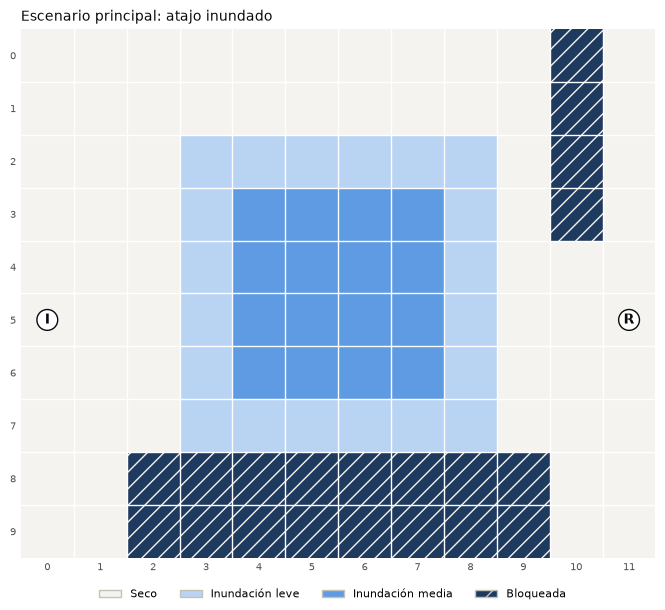

In [4]:
terreno, inicio, refugios = escenario_atajo_inundado()
fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")
dibujar_terreno(terreno, inicio, refugios, titulo="Escenario principal: atajo inundado", ax=ax)
leyenda(fig, con_ruta=False)
plt.show()

## 3. Estrategias de búsqueda

Todas las estrategias reciben lo mismo (`terreno, inicio, refugios, lam`) y devuelven un `Resultado` con la misma estructura. Para que la comparación sea justa, todas miden el trabajo con los mismos criterios:

| Métrica | Qué mide |
|---|---|
| **Nodos generados** | Cuántas celdas se agregaron a la frontera (incluye el inicio). |
| **Nodos expandidos** | Cuántas celdas se sacaron de la frontera y se revisaron sus vecinos. Es la medida principal de trabajo. |
| **Frontera máxima** | El mayor número de celdas pendientes al mismo tiempo. Indica cuánta memoria usó la búsqueda. |
| **Tiempo** | Milisegundos medidos con `time.perf_counter()`. Varía entre ejecuciones y equipos. |

En todas, la prueba de meta se hace **al sacar** la celda de la frontera, no al agregarla. Así las métricas son comparables entre algoritmos.

### 3.1 Búsqueda no informada (BFS, DFS, UCS)
_Responsable: Hector Martínez Sánchez_

Las estrategias no informadas no saben dónde está el refugio: solo exploran a partir del inicio. La diferencia entre ellas es **qué celda de la frontera eligen expandir primero**.

| Algoritmo | Estructura de la frontera | Expande primero | ¿Usa el riesgo para decidir? | Garantiza |
|---|---|---|---|---|
| **BFS** (anchura) | Cola (FIFO) | La celda que lleva más tiempo esperando | No | La ruta con **menos pasos** |
| **DFS** (profundidad) | Pila (LIFO) | La celda agregada más recientemente | No | Solo **encontrar una ruta**, si existe |
| **UCS** (costo uniforme) | Cola de prioridad por costo acumulado `g` | La celda con menor costo acumulado | **Sí** | La ruta de **menor costo** |

- **BFS** avanza por "capas": primero todas las celdas a 1 paso, luego a 2, y así sucesivamente. Por eso la primera vez que llega al refugio lo hace con el mínimo de pasos, aunque cruce agua.
- **DFS** sigue un camino hasta el fondo antes de regresar. Encuentra una ruta, pero puede ser muy larga y dar muchas vueltas. Se incluye como contraste: **encontrar una ruta no es lo mismo que encontrar una ruta conveniente.**
- **UCS** siempre expande la celda más barata hasta el momento, con costo `1 + λ·riesgo` por paso. Es la única de las tres que considera el riesgo al decidir.

En BFS y DFS, λ no cambia la ruta: solo se usa para **reportar** cuánto cuesta la ruta que encontraron.

In [5]:
from src.escenarios import escenario_atajo_inundado
from src.busqueda_no_informada import bfs, dfs, ucs
from src.validacion import validar_resultado


def tabla_resultados(resultados, terreno, inicio, refugios, lam):
    """Convierte una lista de Resultado en una tabla y valida cada ruta."""
    filas = []
    for r in resultados:
        valida, _ = validar_resultado(terreno, inicio, refugios, r, lam)
        filas.append({
            "Algoritmo": r.algoritmo,
            "Encontró ruta": "Sí" if r.encontrada else "No",
            "Ruta válida": "Sí" if valida else "No",
            "Costo": r.costo,
            "Pasos": r.pasos,
            "Riesgo acumulado": r.riesgo_acumulado,
            "Nodos expandidos": r.nodos_expandidos,
            "Nodos generados": r.nodos_generados,
            "Frontera máx.": r.frontera_max,
            "Tiempo (ms)": round(r.tiempo_ms, 3),
        })
    return pd.DataFrame(filas).set_index("Algoritmo")


terreno, inicio, refugios = escenario_atajo_inundado()
resultados_no_inf = [alg(terreno, inicio, refugios, lam=1.0) for alg in (bfs, dfs, ucs)]
tabla_resultados(resultados_no_inf, terreno, inicio, refugios, lam=1.0)

,Encontró ruta,Ruta válida,Costo,Pasos,Riesgo acumulado,Nodos expandidos,Nodos generados,Frontera máx.,Tiempo (ms)
Algoritmo,,,,,,,,,
BFS,Sí,Sí,25.0,11,14.0,81,88,10,0.086
DFS,Sí,Sí,151.0,83,68.0,93,166,72,0.092
UCS,Sí,Sí,19.0,19,0.0,89,96,11,0.193


#### ¿Qué pasa si el riesgo no importa (λ = 0)?
Con λ = 0 todos los pasos cuestan 1, así que el costo de una ruta es igual a su número de pasos. En ese caso UCS debería comportarse como BFS.

In [6]:
bfs_0 = bfs(terreno, inicio, refugios, lam=0)
ucs_0 = ucs(terreno, inicio, refugios, lam=0)

display(tabla_resultados([bfs_0, ucs_0], terreno, inicio, refugios, lam=0))
print("¿Misma ruta exacta?", bfs_0.ruta == ucs_0.ruta)

,Encontró ruta,Ruta válida,Costo,Pasos,Riesgo acumulado,Nodos expandidos,Nodos generados,Frontera máx.,Tiempo (ms)
Algoritmo,,,,,,,,,
BFS,Sí,Sí,11.0,11,14.0,81,88,10,0.078
UCS,Sí,Sí,11.0,11,14.0,81,88,10,0.177


¿Misma ruta exacta? True


**Observaciones**

- **BFS** encuentra la ruta con menos pasos (11), pero cruza el centro de la inundación: riesgo acumulado 14, costo 25.
- **UCS** da 8 pasos más (19), pero con riesgo 0 y costo 19. Es la ruta más conveniente con λ = 1.
- **DFS** encuentra una ruta válida, pero es la peor: 83 pasos, costo 151 y la frontera más grande (72). Demuestra que encontrar una ruta no basta.
- UCS hizo un poco más de trabajo que BFS (89 contra 81 nodos expandidos) porque tuvo que explorar los rodeos. Considerar el riesgo tiene un costo computacional, aunque aquí es pequeño.
- Con **λ = 0**, UCS y BFS dan exactamente la misma ruta y el mismo trabajo. Esto confirma que la diferencia entre ambos viene **solo** del riesgo: UCS es una generalización de BFS en la que los pasos pueden tener distinto costo.

### 3.2 Búsqueda informada (Greedy Best-First, A*)
_Responsable: Gildardo Emmanuel González García_

Las estrategias informadas usan una **heurística** `h(n)`, que es una estimación de cuánto falta para llegar al refugio. Con ella deciden qué celda expandir primero.

**Heurística utilizada: distancia Manhattan al refugio más cercano**

$$h(n) = \min_{r \in \text{refugios}} \big(|fila_n - fila_r| + |columna_n - columna_r|\big)$$

Esta heurística es **admisible**, es decir, nunca sobreestima el costo real, porque:
1. Sin movimientos diagonales se necesitan **al menos** `|Δfila| + |Δcolumna|` pasos para llegar.
2. Cada paso cuesta **como mínimo 1** (cuando el riesgo es 0), así que el costo real es mayor o igual que el número de pasos.

También es **consistente**: entre dos celdas vecinas, `h` cambia como máximo en 1, y cada paso cuesta al menos 1. Esto garantiza que A\* con conjunto de cerrados encuentre la ruta óptima.

| Algoritmo | Ordena la frontera por | ¿Usa el riesgo para decidir? | Garantiza |
|---|---|---|---|
| **Greedy Best-First** | `h(n)`: lo que *parece* más cercano | No | Nada; puede dar una ruta mala |
| **A\*** | `f(n) = g(n) + h(n)`: costo real acumulado + estimación | **Sí**, a través de `g` | La ruta de **menor costo** (igual que UCS) |

- **Greedy** solo mira hacia el refugio. Avanza en línea recta aunque haya agua, porque ignora lo que lleva gastado.
- **A\*** combina el costo real con riesgo (`g`, como UCS) con la heurística (`h`, como Greedy). Obtiene la misma ruta óptima que UCS, pero la heurística le permite descartar direcciones que se alejan del refugio y **expandir menos nodos**.

In [7]:
from src.busqueda_informada import greedy, a_estrella

resultados_inf = [alg(terreno, inicio, refugios, lam=1.0) for alg in (greedy, a_estrella)]
tabla_resultados(resultados_inf, terreno, inicio, refugios, lam=1.0)

,Encontró ruta,Ruta válida,Costo,Pasos,Riesgo acumulado,Nodos expandidos,Nodos generados,Frontera máx.,Tiempo (ms)
Algoritmo,,,,,,,,,
Greedy,Sí,Sí,25.0,11,14.0,11,34,23,0.033
A*,Sí,Sí,19.0,19,0.0,48,84,31,0.158


**Observaciones**

- **Greedy** expande solo 11 nodos, el mínimo posible para una ruta de 11 pasos: va directo al refugio. Pero cruza el centro de la inundación y su costo es 25, igual que BFS.
- **A\*** obtiene la misma ruta óptima que UCS (costo 19, riesgo 0), pero expande **48 nodos en lugar de 89**: casi la mitad del trabajo. Esa es la ventaja de una heurística admisible.
- Usar una heurística no basta para obtener rutas convenientes. Lo que importa es **cómo se combina** con el costo real: Greedy la usa sola, A\* la suma al costo con riesgo.

## 4. Visualización del terreno y las rutas
_Responsable: Ismael Alexander Hidalgo Aguilando_

- Mapa con colores por nivel de inundación.
- Rutas de cada algoritmo dibujadas sobre el terreno.

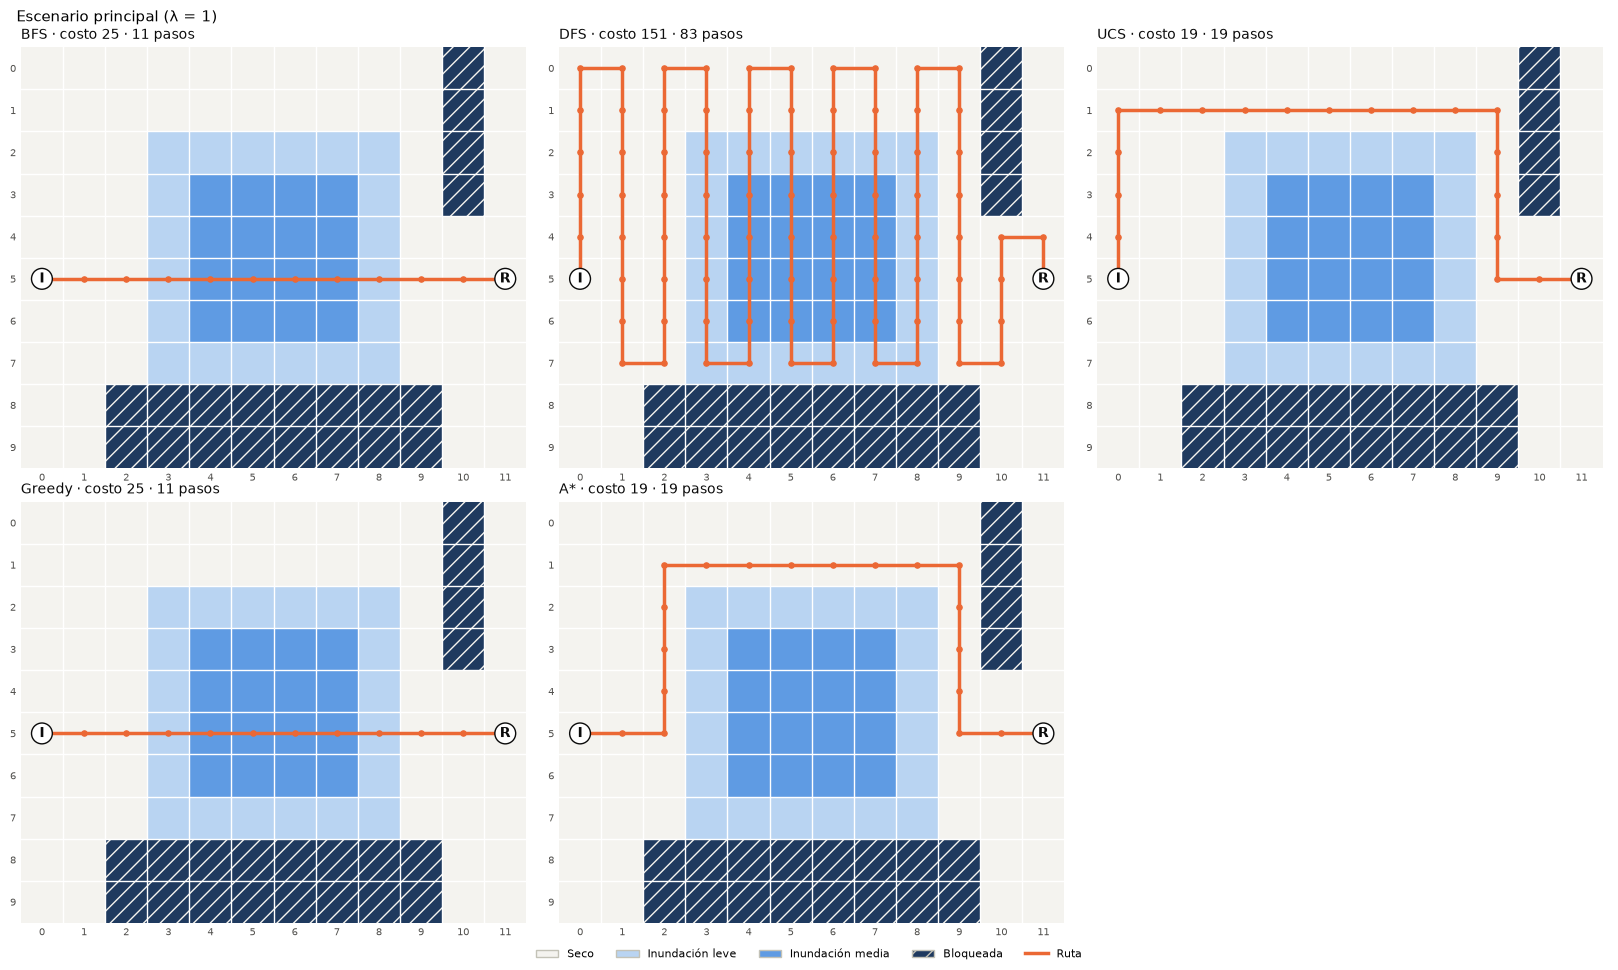

In [8]:
from src.busqueda_no_informada import bfs, dfs, ucs
from src.busqueda_informada import greedy, a_estrella

ALGORITMOS = [bfs, dfs, ucs, greedy, a_estrella]

resultados = [alg(terreno, inicio, refugios, lam=1.0) for alg in ALGORITMOS]
fig = comparar_rutas(terreno, inicio, refugios, resultados)
fig.suptitle("Escenario principal (λ = 1)", x=0.01, ha="left", fontsize=11)
plt.show()

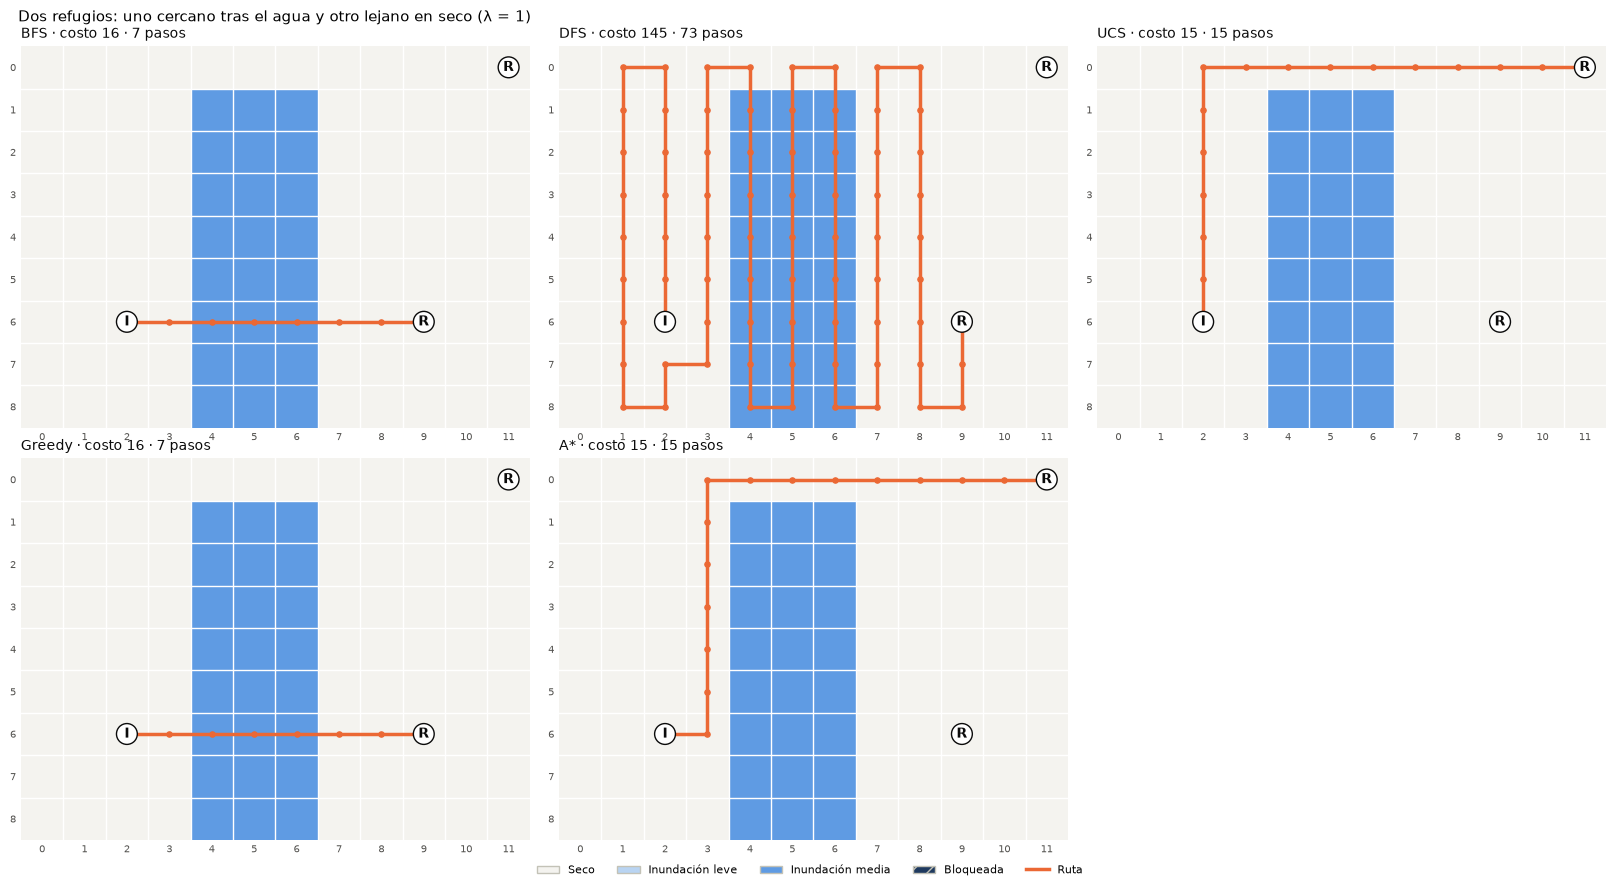

In [9]:
terreno_2, inicio_2, refugios_2 = escenario_dos_refugios()
resultados_2 = [alg(terreno_2, inicio_2, refugios_2, lam=1.0) for alg in ALGORITMOS]
fig = comparar_rutas(terreno_2, inicio_2, refugios_2, resultados_2)
fig.suptitle("Dos refugios: uno cercano tras el agua y otro lejano en seco (λ = 1)",
             x=0.01, ha="left", fontsize=11)
plt.show()

**Observaciones**

- En el escenario principal, BFS y Greedy cruzan la zona inundada: 11 pasos, pero costo 25. UCS y A* la rodean por el norte: 19 pasos, costo 19. La ruta más corta no es la más conveniente.
- DFS encuentra una ruta, pero es muy larga y atraviesa agua varias veces. Encontrar una ruta no es lo mismo que encontrar una ruta conveniente.
- En el escenario de dos refugios, BFS y Greedy eligen el refugio cercano cruzando el agua (costo 16). UCS y A* eligen el refugio lejano por terreno seco (costo 15).

## 5. Comparación de algoritmos
_Responsable: Gildardo Emmanuel González García_

Se ejecutan los cinco algoritmos en los dos escenarios con λ = 1.

- Todas las cifras de costo y trabajo salen de ejecuciones reales en este notebook.
- Como el tiempo varía entre ejecuciones, se reporta la **mediana de 30 ejecuciones** de cada algoritmo.
- Cada ruta se comprueba con el validador independiente (columna "Ruta válida").

In [10]:
import statistics
from src.escenarios import escenario_atajo_inundado, escenario_dos_refugios

ALGORITMOS = [bfs, dfs, ucs, greedy, a_estrella]
ESCENARIOS = {
    "Atajo inundado": escenario_atajo_inundado,
    "Dos refugios": escenario_dos_refugios,
}
REPETICIONES = 30
LAM = 1.0


def comparar_escenario(nombre, crear_escenario, lam=LAM, repeticiones=REPETICIONES):
    """Ejecuta todos los algoritmos en un escenario y mide el tiempo mediano."""
    t, i, r = crear_escenario()
    resultados = [alg(t, i, r, lam=lam) for alg in ALGORITMOS]
    tabla = tabla_resultados(resultados, t, i, r, lam).drop(columns="Tiempo (ms)")
    tabla["Tiempo mediano (ms)"] = [
        round(statistics.median(alg(t, i, r, lam=lam).tiempo_ms for _ in range(repeticiones)), 3)
        for alg in ALGORITMOS
    ]
    tabla.insert(0, "Escenario", nombre)
    return tabla


comparacion = pd.concat([comparar_escenario(n, f) for n, f in ESCENARIOS.items()])
comparacion

,Escenario,Encontró ruta,Ruta válida,Costo,Pasos,Riesgo acumulado,Nodos expandidos,Nodos generados,Frontera máx.,Tiempo mediano (ms)
Algoritmo,,,,,,,,,,
BFS,Atajo inundado,Sí,Sí,25.0,11,14.0,81,88,10,0.072
DFS,Atajo inundado,Sí,Sí,151.0,83,68.0,93,166,72,0.091
UCS,Atajo inundado,Sí,Sí,19.0,19,0.0,89,96,11,0.203
Greedy,Atajo inundado,Sí,Sí,25.0,11,14.0,11,34,23,0.022
A*,Atajo inundado,Sí,Sí,19.0,19,0.0,48,84,31,0.140
BFS,Dos refugios,Sí,Sí,16.0,7,9.0,64,74,12,0.062
DFS,Dos refugios,Sí,Sí,145.0,73,72.0,83,158,75,0.086
UCS,Dos refugios,Sí,Sí,15.0,15,0.0,79,90,12,0.188
Greedy,Dos refugios,Sí,Sí,16.0,7,9.0,7,23,16,0.016


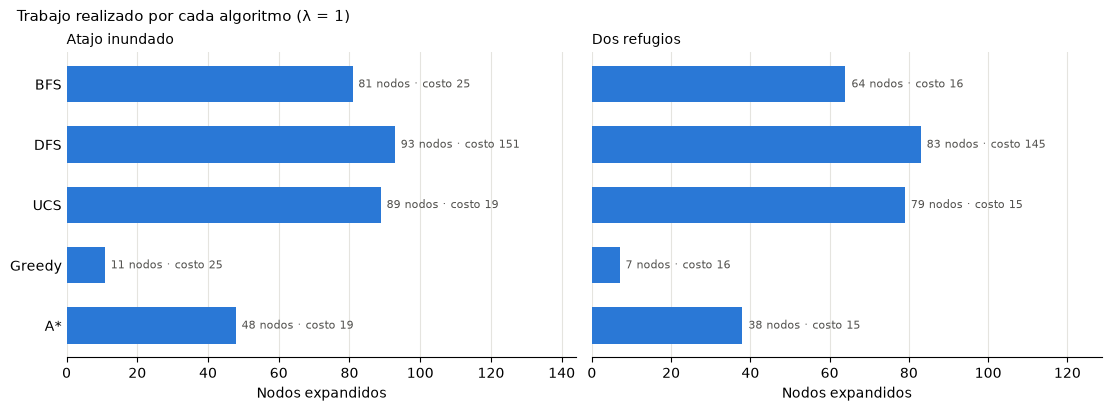

In [11]:
COLOR_BARRA = "#2a78d6"

fig, ejes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained", sharey=True)
for ax, (nombre, datos) in zip(ejes, comparacion.groupby("Escenario", sort=False)):
    barras = ax.barh(list(datos.index), datos["Nodos expandidos"], color=COLOR_BARRA, height=0.6)
    for barra, exp, costo in zip(barras, datos["Nodos expandidos"], datos["Costo"]):
        ax.text(barra.get_width() + 1.5, barra.get_y() + barra.get_height() / 2,
                f"{exp} nodos · costo {costo:g}", va="center", fontsize=8, color="#52514e")
    ax.set_title(nombre, loc="left", fontsize=10)
    ax.set_xlabel("Nodos expandidos")
    ax.set_xlim(0, datos["Nodos expandidos"].max() * 1.55)
    ax.grid(axis="x", color="#e5e4df", linewidth=0.8)
    ax.set_axisbelow(True)
    for lado in ("top", "right", "left"):
        ax.spines[lado].set_visible(False)
    ax.tick_params(axis="y", length=0)

ejes[0].invert_yaxis()  # BFS arriba; con sharey basta invertir una vez
fig.suptitle("Trabajo realizado por cada algoritmo (λ = 1)", x=0.01, ha="left", fontsize=11)
plt.show()

**Conclusiones de la comparación**

| | Ruta conveniente (menor costo) | Poco trabajo |
|---|---|---|
| **BFS** | No: minimiza pasos, no riesgo | No |
| **DFS** | No: rutas muy largas | No |
| **UCS** | **Sí** | No |
| **Greedy** | No: va directo aunque cruce agua | **Sí** |
| **A\*** | **Sí** | **Sí**, comparado con UCS |

1. **Solo UCS y A\* encuentran la ruta conveniente**, porque son los únicos que incluyen el riesgo en el costo que optimizan. En ambos escenarios obtienen exactamente el mismo costo (19 y 15).
2. **A\* hace aproximadamente la mitad del trabajo que UCS:** 48 contra 89 nodos expandidos en el escenario principal, y 38 contra 79 en el de dos refugios. Es la mejor estrategia del prototipo.
3. **Greedy es el más rápido, pero no es confiable:** expande el mínimo de nodos y elige la misma ruta riesgosa que BFS.
4. En **dos refugios**, BFS y Greedy eligen el refugio cercano cruzando el agua (costo 16). UCS y A\* eligen el refugio lejano por terreno seco (costo 15). El riesgo cambió **a qué refugio** conviene ir, no solo por dónde.
5. **El tiempo depende del equipo y no siempre sigue a los nodos expandidos.** Por eso los nodos expandidos son la medida de trabajo más justa entre algoritmos.

### 5.1 Efecto del peso del riesgo (λ)
_Responsable: Gildardo Emmanuel González García_

Se ejecutan UCS y A\* en el escenario principal con **61 valores de λ** (de 0 a 3, cada 0.05) y se registra qué ruta elige cada uno.

El objetivo es ver con ejecuciones reales:
1. en qué valores de λ cambia la decisión del algoritmo;
2. si A\* sigue obteniendo el mismo costo óptimo que UCS para cualquier λ.

In [12]:
import math
from dataclasses import replace

terreno, inicio, refugios = escenario_atajo_inundado()
VALORES_LAMBDA = np.round(np.arange(0, 3.01, 0.05), 2)

filas = []
for lam in VALORES_LAMBDA:
    r_ucs = ucs(terreno, inicio, refugios, lam=float(lam))
    r_a = a_estrella(terreno, inicio, refugios, lam=float(lam))
    filas.append({
        "λ": float(lam),
        "Pasos": r_ucs.pasos,
        "Riesgo": r_ucs.riesgo_acumulado,
        "Costo UCS": r_ucs.costo,
        "Costo A*": r_a.costo,
        "Expandidos UCS": r_ucs.nodos_expandidos,
        "Expandidos A*": r_a.nodos_expandidos,
        "ruta": tuple(r_ucs.ruta),
    })
barrido = pd.DataFrame(filas)

mismo_costo = all(math.isclose(u, a) for u, a in zip(barrido["Costo UCS"], barrido["Costo A*"]))
print(f"Valores de λ probados: {len(barrido)}")
print(f"¿A* obtuvo el mismo costo que UCS en todos? {mismo_costo}")
print(f"Nodos expandidos promedio: UCS {barrido['Expandidos UCS'].mean():.1f}, "
      f"A* {barrido['Expandidos A*'].mean():.1f}")

# Filas donde la ruta elegida por UCS cambia respecto al λ anterior
cambios = barrido[barrido["ruta"] != barrido["ruta"].shift()]
cambios[["λ", "Pasos", "Riesgo", "Costo UCS", "Expandidos UCS", "Expandidos A*"]]

Valores de λ probados: 61
¿A* obtuvo el mismo costo que UCS en todos? True
Nodos expandidos promedio: UCS 80.3, A* 38.7


,λ,Pasos,Riesgo,Costo UCS,Expandidos UCS,Expandidos A*
0,0.00,11,14.0,11.0,81,11
11,0.55,15,6.0,18.3,94,45
14,0.70,19,0.0,19.0,94,52


In [13]:
# Las rutas distintas que eligió UCS en el barrido
rutas = barrido.drop_duplicates("ruta")[["Pasos", "Riesgo", "ruta"]].reset_index(drop=True)
rutas["Nombre"] = [f"Ruta {chr(65 + k)}" for k in range(len(rutas))]

# El costo de cada ruta es una recta: pasos + λ·riesgo.
# La decisión cambia donde se cruzan dos rectas consecutivas.
umbrales = []
for k in range(len(rutas) - 1):
    a, b = rutas.iloc[k], rutas.iloc[k + 1]
    umbrales.append({
        "Cambio": f"{a.Nombre} → {b.Nombre}",
        "λ donde empatan": round((b.Pasos - a.Pasos) / (a.Riesgo - b.Riesgo), 3),
    })

display(rutas[["Nombre", "Pasos", "Riesgo"]])
pd.DataFrame(umbrales)

,Nombre,Pasos,Riesgo
0,Ruta A,11,14.0
1,Ruta B,15,6.0
2,Ruta C,19,0.0


,Cambio,λ donde empatan
0,Ruta A → Ruta B,0.500
1,Ruta B → Ruta C,0.667


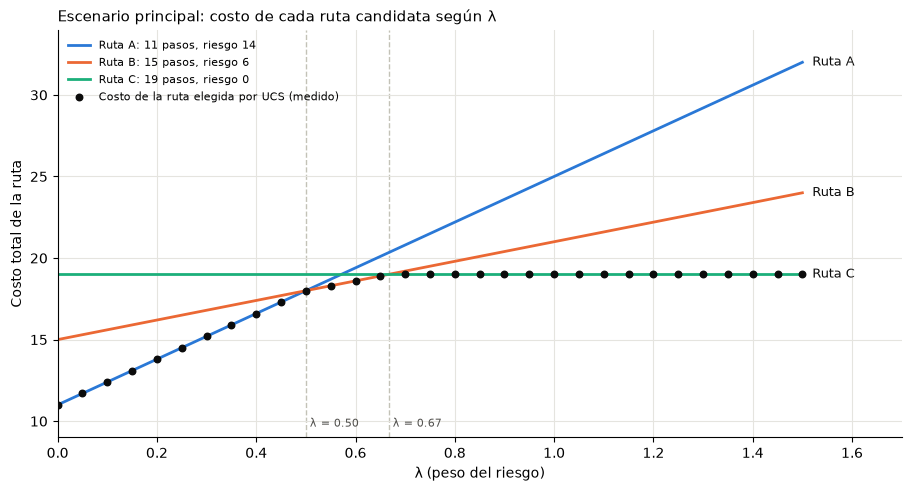

In [14]:
COLORES_RUTA = ["#2a78d6", "#eb6834", "#1baf7a"]
x = np.linspace(0, 1.5, 200)

fig, ax = plt.subplots(figsize=(9, 4.8), layout="constrained")
for (_, ruta), color in zip(rutas.iterrows(), COLORES_RUTA):
    ax.plot(x, ruta.Pasos + x * ruta.Riesgo, color=color, linewidth=2,
            label=f"{ruta.Nombre}: {ruta.Pasos} pasos, riesgo {ruta.Riesgo:g}")
    ax.text(1.52, ruta.Pasos + 1.5 * ruta.Riesgo, ruta.Nombre, color="#0b0b0b",
            fontsize=9, va="center")

visibles = barrido[barrido["λ"] <= 1.5]
ax.scatter(visibles["λ"], visibles["Costo UCS"], s=22, color="#0b0b0b", zorder=3,
           label="Costo de la ruta elegida por UCS (medido)")

for u in umbrales:
    ax.axvline(u["λ donde empatan"], color="#c3c2b7", linewidth=1, linestyle="--", zorder=0)
    ax.text(u["λ donde empatan"], 9.5, f" λ = {u['λ donde empatan']:.2f}",
            fontsize=8, color="#52514e", va="bottom")

ax.set_xlim(0, 1.7)
ax.set_ylim(9, 34)
ax.set_xlabel("λ (peso del riesgo)")
ax.set_ylabel("Costo total de la ruta")
ax.grid(color="#e5e4df", linewidth=0.8)
ax.set_axisbelow(True)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
ax.legend(loc="upper left", frameon=False, fontsize=8)
ax.set_title("Escenario principal: costo de cada ruta candidata según λ", loc="left", fontsize=11)
plt.show()

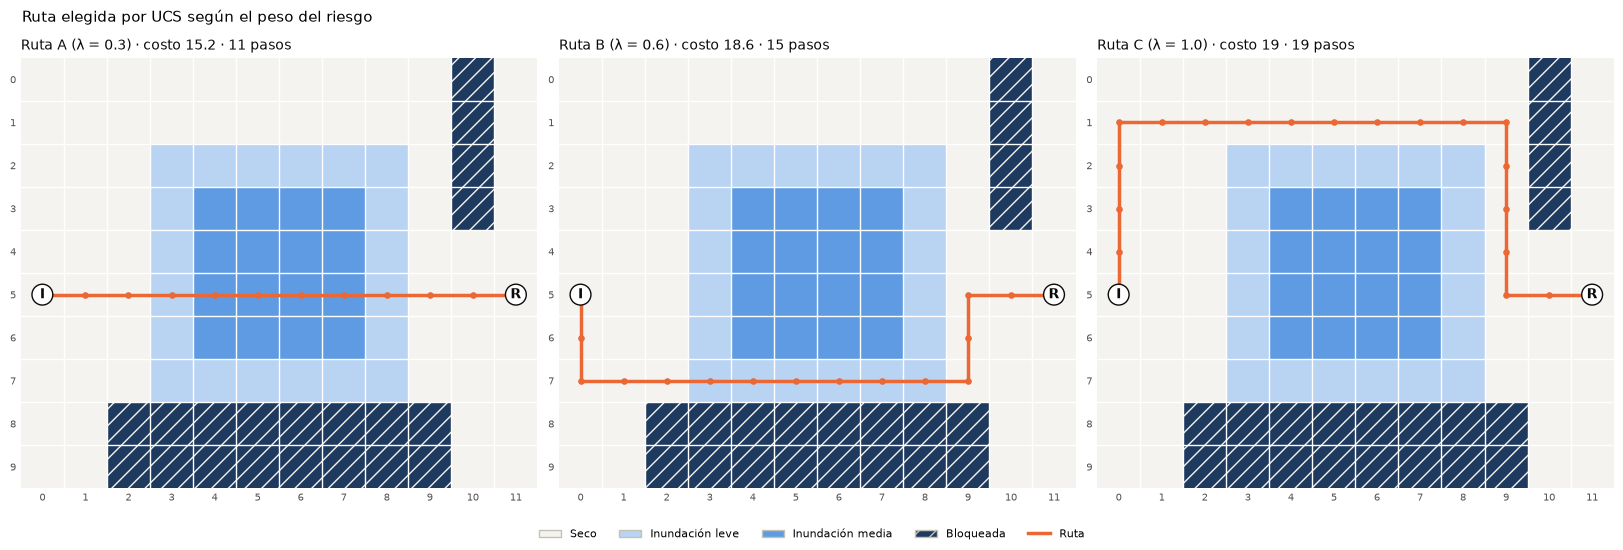

In [15]:
ejemplos = []
for lam, nombre in ((0.3, "Ruta A"), (0.6, "Ruta B"), (1.0, "Ruta C")):
    r = ucs(terreno, inicio, refugios, lam=lam)
    ejemplos.append(replace(r, algoritmo=f"{nombre} (λ = {lam})"))

fig = comparar_rutas(terreno, inicio, refugios, ejemplos)
fig.suptitle("Ruta elegida por UCS según el peso del riesgo", x=0.01, ha="left", fontsize=11)
plt.show()

**Observaciones**

1. **La decisión no es todo o nada.** Al aumentar λ, UCS pasa por tres rutas distintas:
   - **λ < 0.5 → Ruta A:** cruza el centro de la inundación (11 pasos, riesgo 14). El riesgo pesa poco y conviene la ruta corta.
   - **0.5 < λ < 0.67 → Ruta B:** evita el agua media, pero camina por la orilla leve (15 pasos, riesgo 6). Es un punto intermedio.
   - **λ > 0.67 → Ruta C:** rodea todo el agua (19 pasos, riesgo 0). A partir de aquí la ruta ya no cambia, aunque λ siga creciendo, porque no existe una ruta más segura.
2. **Los cambios ocurren exactamente donde predice el modelo.** El costo de cada ruta es la recta `pasos + λ·riesgo`, y los puntos medidos siguen siempre la recta más baja. Los umbrales se calculan con los pasos y el riesgo de cada ruta medidos en el barrido:
   - de A a B: (15 − 11) / (14 − 6) = **0.5**;
   - de B a C: (19 − 15) / (6 − 0) = **0.667**.
3. **En λ = 0.5 hay empate exacto** (costo 18 para las rutas A y B). Ambas son óptimas y el algoritmo puede devolver cualquiera de las dos.
4. **A\* obtuvo el mismo costo que UCS en los 61 valores de λ**, con menos de la mitad de nodos expandidos en promedio (38.7 contra 80.3). La heurística sigue siendo admisible para cualquier λ ≥ 0, porque cada paso sigue costando al menos 1.

**Respuesta a la pregunta guía con datos:** cuando una ruta es más corta y otra atraviesa menos riesgo, el sistema elige la de menor `pasos + λ·riesgo`. En este escenario, la ruta corta (11 pasos) solo gana si λ < 0.5. Con λ = 1, el valor usado en el resto del notebook, gana la ruta de 19 pasos sin riesgo.

## 6. Pruebas
_Responsables: Hector Martínez Sánchez (6.1–6.3) y Anthony Oziel Ramos López (6.4–6.6)_

Cada prueba:
1. prepara un escenario modificando una **copia** del terreno, sin tocar el original;
2. ejecuta los cinco algoritmos;
3. comprueba **cada** resultado con el validador independiente (`validar_resultado`);
4. verifica con `assert` las condiciones específicas de la prueba.

Si alguna condición no se cumple, la celda se detiene con un error que explica qué falló. Si todas se cumplen, imprime **PRUEBA SUPERADA**.

In [16]:
from src.terreno import colocar_zona
from src.validacion import validar_resultado, hay_camino


def ejecutar_prueba(terreno, inicio, refugios, lam=1.0):
    """Ejecuta los cinco algoritmos y exige que el validador apruebe cada resultado."""
    resultados = [alg(terreno, inicio, refugios, lam=lam) for alg in ALGORITMOS]
    for r in resultados:
        valida, errores = validar_resultado(terreno, inicio, refugios, r, lam)
        assert valida, f"{r.algoritmo} produjo un resultado inválido: {errores}"
    return resultados

### 6.1 Existe una ruta disponible hasta el refugio

**Qué se comprueba:** en el escenario principal hay camino al refugio, así que:
- todos los algoritmos deben encontrar una ruta válida;
- UCS y A\* deben obtener el mismo costo, que debe ser el menor de todos.

In [17]:
terreno, inicio, refugios = escenario_atajo_inundado()
res_61 = ejecutar_prueba(terreno, inicio, refugios)
por_alg_61 = {r.algoritmo: r for r in res_61}

assert all(r.encontrada for r in res_61), "Algún algoritmo no encontró ruta"
assert math.isclose(por_alg_61["UCS"].costo, por_alg_61["A*"].costo), "UCS y A* difieren en costo"
assert all(por_alg_61["UCS"].costo <= r.costo for r in res_61), "Hay una ruta más barata que la de UCS"

display(tabla_resultados(res_61, terreno, inicio, refugios, lam=1.0))
print("PRUEBA 6.1 SUPERADA: todos encontraron ruta válida y UCS/A* obtienen el costo mínimo (19).")

,Encontró ruta,Ruta válida,Costo,Pasos,Riesgo acumulado,Nodos expandidos,Nodos generados,Frontera máx.,Tiempo (ms)
Algoritmo,,,,,,,,,
BFS,Sí,Sí,25.0,11,14.0,81,88,10,0.079
DFS,Sí,Sí,151.0,83,68.0,93,166,72,0.094
UCS,Sí,Sí,19.0,19,0.0,89,96,11,0.197
Greedy,Sí,Sí,25.0,11,14.0,11,34,23,0.024
A*,Sí,Sí,19.0,19,0.0,48,84,31,0.135


PRUEBA 6.1 SUPERADA: todos encontraron ruta válida y UCS/A* obtienen el costo mínimo (19).


### 6.2 Se bloquea una zona que formaba parte de la ruta

**Qué se comprueba:** se bloquean las celdas (0,5) y (1,5), por donde pasaba la ruta óptima, y se vuelve a buscar.
- La zona bloqueada debe estar en la ruta original de UCS y A\*. Si no estuviera, la prueba no probaría nada.
- Ninguna ruta nueva puede pisar la zona bloqueada.
- El nuevo costo óptimo **no puede ser menor** que el anterior: quitar opciones nunca abarata la mejor ruta. Si bajara, habría un error en la búsqueda.

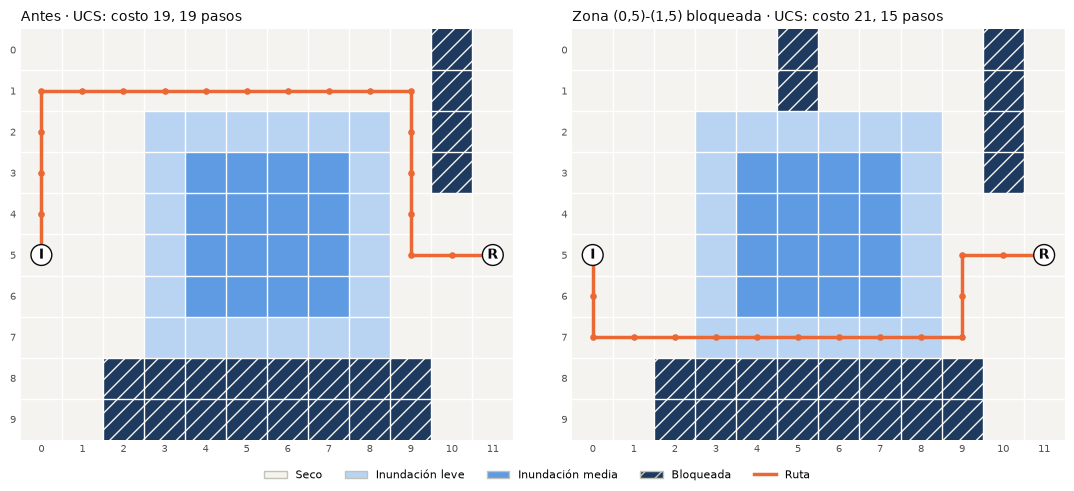

,Encontró ruta,Ruta válida,Costo,Pasos,Riesgo acumulado,Nodos expandidos,Nodos generados,Frontera máx.,Tiempo (ms)
Algoritmo,,,,,,,,,
BFS,Sí,Sí,25.0,11,14.0,79,86,10,0.076
DFS,Sí,Sí,147.0,79,68.0,91,160,68,0.092
UCS,Sí,Sí,21.0,15,6.0,91,94,11,0.194
Greedy,Sí,Sí,25.0,11,14.0,11,34,23,0.024
A*,Sí,Sí,21.0,15,6.0,52,77,19,0.136


PRUEBA 6.2 SUPERADA: la ruta óptima cambió de costo 19 a 21 y ninguna ruta pisa la zona bloqueada.


In [18]:
ZONA_BLOQUEADA = ((0, 5), (1, 5))
terreno_62 = colocar_zona(terreno, *ZONA_BLOQUEADA, BLOQUEADA)
celdas_bloqueadas = [(0, 5), (1, 5)]

for nombre in ("UCS", "A*"):
    assert any(c in por_alg_61[nombre].ruta for c in celdas_bloqueadas), \
        f"La zona no estaba en la ruta original de {nombre}"

res_62 = ejecutar_prueba(terreno_62, inicio, refugios)
por_alg_62 = {r.algoritmo: r for r in res_62}

for r in res_62:
    assert r.encontrada, f"{r.algoritmo} no encontró ruta alternativa"
    assert not any(c in r.ruta for c in celdas_bloqueadas), f"{r.algoritmo} pisa la zona bloqueada"
for nombre in ("UCS", "A*"):
    assert por_alg_62[nombre].costo >= por_alg_61[nombre].costo, \
        f"{nombre}: el costo bajó al bloquear una zona"

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.8), layout="constrained")
antes, despues = por_alg_61["UCS"], por_alg_62["UCS"]
dibujar_terreno(terreno, inicio, refugios, antes.ruta,
                f"Antes · UCS: costo {antes.costo:g}, {antes.pasos} pasos", ax=ax1)
dibujar_terreno(terreno_62, inicio, refugios, despues.ruta,
                f"Zona (0,5)-(1,5) bloqueada · UCS: costo {despues.costo:g}, {despues.pasos} pasos", ax=ax2)
leyenda(fig)
plt.show()

display(tabla_resultados(res_62, terreno_62, inicio, refugios, lam=1.0))
print(f"PRUEBA 6.2 SUPERADA: la ruta óptima cambió de costo {antes.costo:g} a {despues.costo:g} "
      f"y ninguna ruta pisa la zona bloqueada.")

### 6.3 El refugio deja de ser accesible

**Qué se comprueba:** se prueban dos formas de dejar el refugio sin acceso.
- **Caso A:** se bloquean las tres celdas vecinas transitables del refugio, que queda rodeado.
- **Caso B:** se inunda por completo la celda del propio refugio.

En ambos casos todos los algoritmos deben responder "sin ruta" sin fallar ni quedarse en un ciclo infinito, y el validador debe confirmar con su propia exploración que realmente no existe camino.

Caso A (rodeado):


,Encontró ruta,Ruta válida,Nodos expandidos
Algoritmo,,,
BFS,No,Sí,92
DFS,No,Sí,92
UCS,No,Sí,92
Greedy,No,Sí,92
A*,No,Sí,92


Caso B (inundado):


,Encontró ruta,Ruta válida,Nodos expandidos
Algoritmo,,,
BFS,No,Sí,99
DFS,No,Sí,99
UCS,No,Sí,99
Greedy,No,Sí,99
A*,No,Sí,99


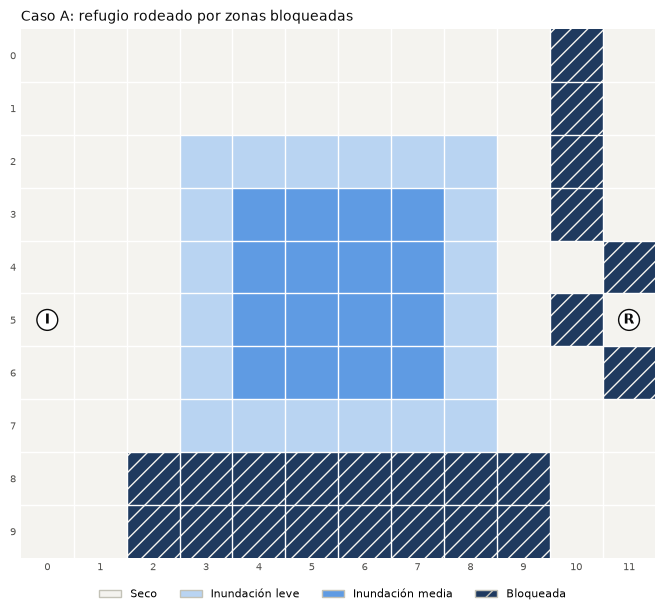

PRUEBA 6.3 SUPERADA: en ambos casos los cinco algoritmos responden 'sin ruta' correctamente.


In [19]:
# Caso A: refugio rodeado
terreno_63a = terreno.copy()
for celda in [(4, 11), (6, 11), (5, 10)]:
    terreno_63a[celda] = BLOQUEADA

# Caso B: el refugio mismo queda inundado
terreno_63b = colocar_zona(terreno, refugios[0], refugios[0], BLOQUEADA)

for nombre_caso, t in (("A (rodeado)", terreno_63a), ("B (inundado)", terreno_63b)):
    assert not hay_camino(t, inicio, refugios), f"Caso {nombre_caso}: sí existe camino"
    res_63 = ejecutar_prueba(t, inicio, refugios)  # el validador confirma cada "sin ruta"
    for r in res_63:
        assert not r.encontrada, f"{r.algoritmo} dice haber encontrado ruta"
        assert r.ruta == [] and r.costo == 0, f"{r.algoritmo} devolvió datos de una ruta inexistente"
    print(f"Caso {nombre_caso}:")
    display(tabla_resultados(res_63, t, inicio, refugios, lam=1.0)
            [["Encontró ruta", "Ruta válida", "Nodos expandidos"]])

fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")
dibujar_terreno(terreno_63a, inicio, refugios, titulo="Caso A: refugio rodeado por zonas bloqueadas", ax=ax)
leyenda(fig, con_ruta=False)
plt.show()

print("PRUEBA 6.3 SUPERADA: en ambos casos los cinco algoritmos responden 'sin ruta' correctamente.")

**Observación:** cuando no hay ruta, los cinco algoritmos expanden **exactamente el mismo número de nodos** (92 en el caso A, 99 en el B). Ese es el número de celdas alcanzables desde el inicio. Para afirmar que no hay ruta, cualquier algoritmo tiene que explorar todo lo alcanzable, sin importar su estrategia. Ni la heurística de A\* ni la de Greedy ahorran trabajo en este caso.

### 6.4 Se modifica el riesgo de una región y se vuelve a buscar

**Qué se comprueba:** se cambia el nivel de inundación de una región y se repite la búsqueda en dos situaciones.
- **Caso A, el agua baja:** el centro pasa de inundación media a leve.
- **Caso B, el agua sube:** el paso norte, que usaba la ruta óptima, pasa de seco a inundación leve.

En ambos casos:
- la ruta elegida por UCS y A\* debe **cambiar**;
- la nueva ruta debe ser **al menos tan barata como la ruta anterior** evaluada en el terreno nuevo. Si la ruta vieja saliera más barata, el algoritmo no habría encontrado la óptima;
- BFS **no debe cambiar**, porque ignora el riesgo;
- el terreno original **no debe modificarse**, para que cada prueba parta del mismo escenario.

In [20]:
terreno, inicio, refugios = escenario_atajo_inundado()
copia_original = terreno.copy()
base_64 = {r.algoritmo: r for r in ejecutar_prueba(terreno, inicio, refugios)}


def costo_en_terreno(t, ruta, lam=1.0):
    """Costo de una ruta fija evaluada en el terreno t (se recalcula aquí, sin usar los algoritmos)."""
    return sum(1 + lam * RIESGO_POR_NIVEL[int(t[c])] for c in ruta[1:])


def comprobar_cambio_de_riesgo(t_nuevo, nombre_caso):
    """Ejecuta los algoritmos en el terreno modificado y verifica las condiciones de la prueba 6.4."""
    nuevo = {r.algoritmo: r for r in ejecutar_prueba(t_nuevo, inicio, refugios)}
    for nombre in ("UCS", "A*"):
        assert nuevo[nombre].ruta != base_64[nombre].ruta, f"{nombre_caso}: {nombre} no cambió de ruta"
        costo_ruta_vieja = costo_en_terreno(t_nuevo, base_64[nombre].ruta)
        assert nuevo[nombre].costo <= costo_ruta_vieja, \
            f"{nombre_caso}: {nombre} eligió una ruta más cara que la anterior"
    assert math.isclose(nuevo["UCS"].costo, nuevo["A*"].costo), f"{nombre_caso}: UCS y A* difieren"
    assert nuevo["BFS"].ruta == base_64["BFS"].ruta, f"{nombre_caso}: BFS cambió aunque ignora el riesgo"
    print(f"{nombre_caso}: UCS pasó de costo {base_64['UCS'].costo:g} ({base_64['UCS'].pasos} pasos) "
          f"a {nuevo['UCS'].costo:g} ({nuevo['UCS'].pasos} pasos). "
          f"La ruta anterior costaría {costo_en_terreno(t_nuevo, base_64['UCS'].ruta):g} en el terreno nuevo.")
    return nuevo


# Caso A: el agua baja en el centro (media -> leve)
terreno_64a = colocar_zona(terreno, (3, 4), (6, 7), LEVE)
res_64a = comprobar_cambio_de_riesgo(terreno_64a, "Caso A (baja el agua)")

Caso A (baja el agua): UCS pasó de costo 19 (19 pasos) a 17 (11 pasos). La ruta anterior costaría 19 en el terreno nuevo.


Caso B (sube el agua): UCS pasó de costo 19 (19 pasos) a 21 (15 pasos). La ruta anterior costaría 28 en el terreno nuevo.


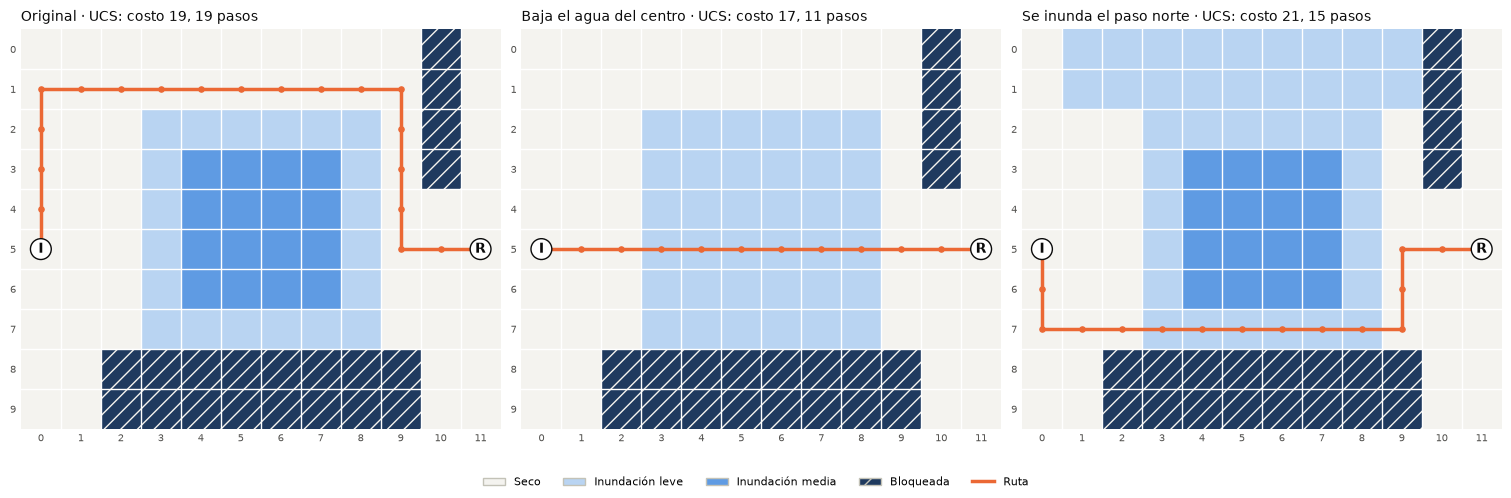

PRUEBA 6.4 SUPERADA: al cambiar el riesgo, UCS y A* cambian de ruta en ambos sentidos, BFS no cambia y el terreno original quedó intacto.


In [21]:
# Caso B: se inunda el paso norte (seco -> leve)
terreno_64b = colocar_zona(terreno, (0, 1), (1, 9), LEVE)
res_64b = comprobar_cambio_de_riesgo(terreno_64b, "Caso B (sube el agua)")

assert np.array_equal(terreno, copia_original), "Las pruebas modificaron el terreno original"

fig, ejes = plt.subplots(1, 3, figsize=(15, 5), layout="constrained")
casos = [
    (terreno, base_64["UCS"], "Original"),
    (terreno_64a, res_64a["UCS"], "Baja el agua del centro"),
    (terreno_64b, res_64b["UCS"], "Se inunda el paso norte"),
]
for ax, (t, r, titulo) in zip(ejes, casos):
    dibujar_terreno(t, inicio, refugios, r.ruta,
                    f"{titulo} · UCS: costo {r.costo:g}, {r.pasos} pasos", ax=ax)
leyenda(fig)
plt.show()

print("PRUEBA 6.4 SUPERADA: al cambiar el riesgo, UCS y A* cambian de ruta en ambos sentidos, "
      "BFS no cambia y el terreno original quedó intacto.")

### 6.5 El camino más corto deja de ser el más conveniente

**Qué se comprueba:** en el mismo escenario se compara la ruta **más corta** (BFS) con la ruta **más conveniente** (UCS).
- Con **λ = 0** (sin riesgo), la ruta más conveniente debe ser la más corta: UCS y BFS dan los mismos pasos.
- Con **λ = 1**, UCS debe elegir una ruta **más larga** pero **más barata** que la de BFS.

Así se demuestra que el sistema distingue entre encontrar una ruta y encontrar una ruta conveniente.

,Pasos,Riesgo acumulado,Costo con λ=1
Ruta,,,
Más corta (BFS),11,14.0,25.0
Más conveniente (UCS),19,0.0,19.0


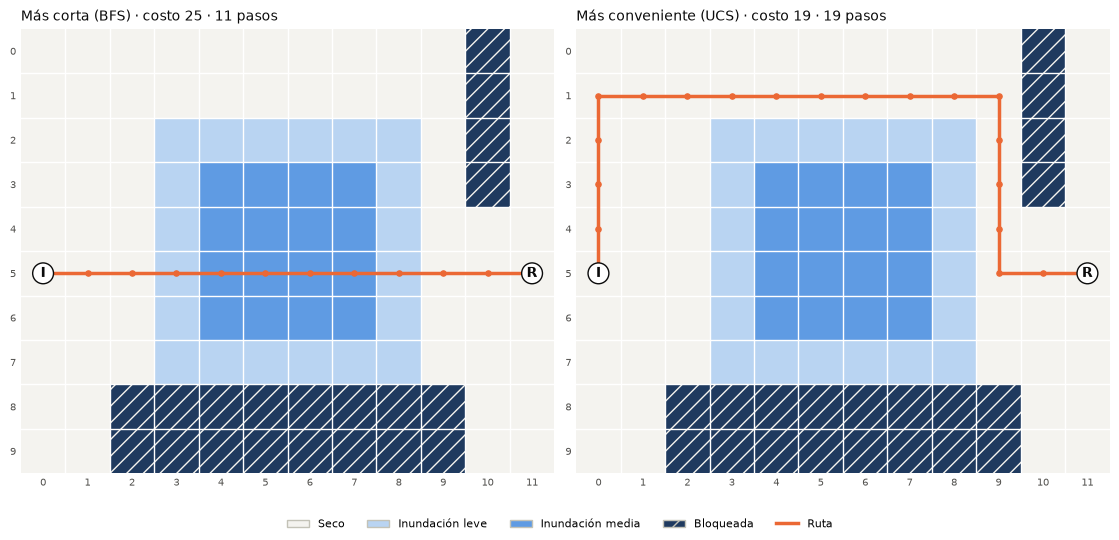

PRUEBA 6.5 SUPERADA: la ruta más corta (11 pasos) cuesta 25; la conveniente da 8 pasos más pero cuesta 19.


In [22]:
mas_corta_0, conveniente_0 = bfs(terreno, inicio, refugios, lam=0), ucs(terreno, inicio, refugios, lam=0)
mas_corta_1, conveniente_1 = bfs(terreno, inicio, refugios, lam=1), ucs(terreno, inicio, refugios, lam=1)

for r, lam in ((mas_corta_0, 0), (conveniente_0, 0), (mas_corta_1, 1), (conveniente_1, 1)):
    assert validar_resultado(terreno, inicio, refugios, r, lam)[0]

# Sin riesgo, lo más corto es lo más conveniente
assert conveniente_0.pasos == mas_corta_0.pasos, "Con λ=0 UCS debería dar la ruta más corta"

# Con riesgo, la conveniente es más larga pero más barata
assert conveniente_1.pasos > mas_corta_1.pasos, "Con λ=1 la ruta conveniente debería ser más larga"
assert conveniente_1.costo < mas_corta_1.costo, "Con λ=1 la ruta conveniente debería costar menos"
assert conveniente_1.riesgo_acumulado < mas_corta_1.riesgo_acumulado

display(pd.DataFrame([
    {"Ruta": "Más corta (BFS)", "Pasos": mas_corta_1.pasos,
     "Riesgo acumulado": mas_corta_1.riesgo_acumulado, "Costo con λ=1": mas_corta_1.costo},
    {"Ruta": "Más conveniente (UCS)", "Pasos": conveniente_1.pasos,
     "Riesgo acumulado": conveniente_1.riesgo_acumulado, "Costo con λ=1": conveniente_1.costo},
]).set_index("Ruta"))

fig = comparar_rutas(terreno, inicio, refugios,
                     [replace(mas_corta_1, algoritmo="Más corta (BFS)"),
                      replace(conveniente_1, algoritmo="Más conveniente (UCS)")],
                     columnas=2)
plt.show()

print(f"PRUEBA 6.5 SUPERADA: la ruta más corta ({mas_corta_1.pasos} pasos) cuesta {mas_corta_1.costo:g}; "
      f"la conveniente da {conveniente_1.pasos - mas_corta_1.pasos} pasos más pero cuesta {conveniente_1.costo:g}.")

### 6.6 Prueba adicional: detección de errores de implementación
_Responsable: Anthony Oziel Ramos López_

**Qué error busca detectar:** A\* depende de que la heurística sea admisible. Si la heurística sobreestima, o si hay un error en cómo A\* actualiza costos o cierra nodos, A\* puede devolver una ruta **válida pero no óptima**. El validador no detecta ese error, porque la ruta sí respeta todas las reglas. Solo se nota comparando contra otro algoritmo que garantice el óptimo.

**Cómo se detecta:** UCS no usa heurística y siempre encuentra el costo mínimo. Si A\* está bien implementado, debe obtener **exactamente el mismo costo** que UCS en cualquier mapa. Se prueba en 300 mapas aleatorios de 15×15 con λ = 0, 1 y 3, en total 900 ejecuciones. También se comprueba que ambos detecten correctamente cuándo no existe camino.

Los mapas se generan con **semillas fijas**, así que cualquier persona que ejecute el notebook obtiene exactamente los mismos mapas y resultados.

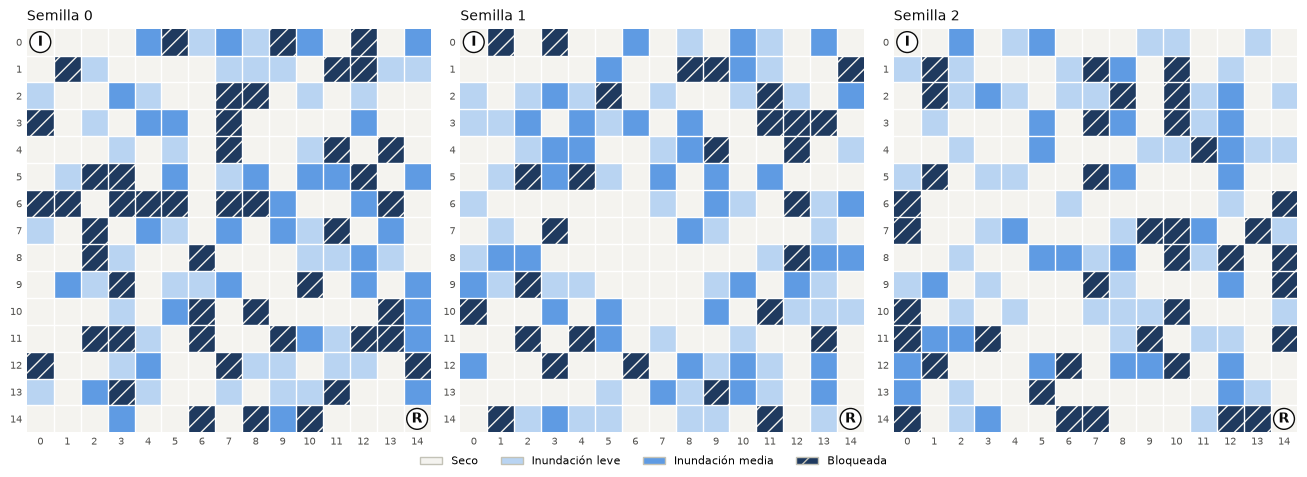

In [23]:
import src.busqueda_informada as busqueda_informada

TAMANO = 15
PROBABILIDADES = [0.5, 0.2, 0.15, 0.15]  # libre, leve, media, bloqueada
INICIO_ALEATORIO = (0, 0)
REFUGIOS_ALEATORIOS = [(TAMANO - 1, TAMANO - 1)]
SEMILLAS = range(300)
LAMBDAS = (0.0, 1.0, 3.0)


def terreno_aleatorio(semilla, tamano=TAMANO):
    """Terreno aleatorio reproducible: la misma semilla siempre da el mismo mapa."""
    rng = np.random.default_rng(semilla)
    t = rng.choice([LIBRE, LEVE, MEDIA, BLOQUEADA], size=(tamano, tamano), p=PROBABILIDADES)
    t[INICIO_ALEATORIO] = LIBRE
    t[REFUGIOS_ALEATORIOS[0]] = LIBRE
    return t


fig, ejes = plt.subplots(1, 3, figsize=(13, 4.6), layout="constrained")
for ax, semilla in zip(ejes, (0, 1, 2)):
    dibujar_terreno(terreno_aleatorio(semilla), INICIO_ALEATORIO, REFUGIOS_ALEATORIOS,
                    titulo=f"Semilla {semilla}", ax=ax)
leyenda(fig, con_ruta=False)
plt.show()

In [24]:
def comparar_a_estrella_con_ucs(semillas, lambdas):
    """Ejecuta UCS y A* en cada mapa y λ, y registra si coinciden."""
    filas = []
    for semilla in semillas:
        t = terreno_aleatorio(semilla)
        existe = hay_camino(t, INICIO_ALEATORIO, REFUGIOS_ALEATORIOS)
        for lam in lambdas:
            r_u = ucs(t, INICIO_ALEATORIO, REFUGIOS_ALEATORIOS, lam=lam)
            r_a = a_estrella(t, INICIO_ALEATORIO, REFUGIOS_ALEATORIOS, lam=lam)
            filas.append({
                "semilla": semilla, "λ": lam, "existe camino": existe,
                "UCS encontró": r_u.encontrada, "A* encontró": r_a.encontrada,
                "costo UCS": r_u.costo, "costo A*": r_a.costo,
                "UCS válida": validar_resultado(t, INICIO_ALEATORIO, REFUGIOS_ALEATORIOS, r_u, lam)[0],
                "A* válida": validar_resultado(t, INICIO_ALEATORIO, REFUGIOS_ALEATORIOS, r_a, lam)[0],
                "expandidos UCS": r_u.nodos_expandidos, "expandidos A*": r_a.nodos_expandidos,
            })
    df = pd.DataFrame(filas)
    df["mismo costo"] = [math.isclose(u, a) for u, a in zip(df["costo UCS"], df["costo A*"])]
    return df


aleatorios = comparar_a_estrella_con_ucs(SEMILLAS, LAMBDAS)
con_camino = aleatorios[aleatorios["existe camino"]]

assert aleatorios["UCS válida"].all() and aleatorios["A* válida"].all(), "Hay rutas inválidas"
assert (aleatorios["UCS encontró"] == aleatorios["existe camino"]).all(), "UCS falló al detectar si hay camino"
assert (aleatorios["A* encontró"] == aleatorios["existe camino"]).all(), "A* falló al detectar si hay camino"
assert aleatorios["mismo costo"].all(), "A* y UCS obtuvieron costos distintos"

print(f"Ejecuciones: {len(aleatorios)} ({len(con_camino)} con camino, "
      f"{len(aleatorios) - len(con_camino)} sin camino)")
print(f"A* expandió igual o menos nodos que UCS en el "
      f"{(con_camino['expandidos A*'] <= con_camino['expandidos UCS']).mean():.0%} de los casos con camino")
display(con_camino.groupby("λ")[["expandidos UCS", "expandidos A*"]].mean().round(1)
        .rename(columns=lambda c: f"Promedio {c}"))
print("PRUEBA 6.6 SUPERADA: A* obtiene exactamente el mismo costo óptimo que UCS en las 900 ejecuciones.")

Ejecuciones: 900 (822 con camino, 78 sin camino)
A* expandió igual o menos nodos que UCS en el 100% de los casos con camino


,Promedio expandidos UCS,Promedio expandidos A*
λ,,
0.0,189.7,38.6
1.0,187.3,106.3
3.0,177.3,123.5


PRUEBA 6.6 SUPERADA: A* obtiene exactamente el mismo costo óptimo que UCS en las 900 ejecuciones.


#### ¿La prueba realmente detecta errores?
Una prueba que nunca falla podría ser una prueba que no revisa nada. Para comprobarlo, se **rompe A\* a propósito**: se multiplica la heurística por 3, lo que la vuelve **no admisible** porque sobreestima. Luego se repite la misma prueba.

Si la prueba sirve, debe encontrar diferencias de costo. Al terminar se restaura la heurística original.

In [25]:
heuristica_original = busqueda_informada.heuristica_manhattan
busqueda_informada.heuristica_manhattan = lambda pos, refugios: 3 * heuristica_original(pos, refugios)
try:
    con_error = comparar_a_estrella_con_ucs(SEMILLAS, LAMBDAS)
finally:
    busqueda_informada.heuristica_manhattan = heuristica_original  # siempre se restaura

fallos = con_error[~con_error["mismo costo"]]
assert len(fallos) > 0, "La prueba NO detectó la heurística rota: no sirve para encontrar este error"
assert busqueda_informada.heuristica_manhattan is heuristica_original

print(f"Con la heurística rota, la prueba encontró {len(fallos)} de {len(con_error)} ejecuciones "
      f"donde A* da un costo mayor que el óptimo.")
print(f"¿El validador detectó algo? Rutas inválidas: {(~con_error['A* válida']).sum()}")
display(fallos[["semilla", "λ", "costo UCS", "costo A*"]].head(5))
print("La heurística original fue restaurada.")

Con la heurística rota, la prueba encontró 604 de 900 ejecuciones donde A* da un costo mayor que el óptimo.
¿El validador detectó algo? Rutas inválidas: 0


,semilla,λ,costo UCS,costo A*
0,0,0.0,28.0,30.0
1,0,1.0,34.0,39.0
3,1,0.0,28.0,30.0
4,1,1.0,32.0,33.0
6,2,0.0,28.0,32.0


La heurística original fue restaurada.


**Resultado:** con la heurística rota, A\* devolvió rutas más caras que el óptimo en **604 de 900** ejecuciones, y la prueba lo detectó. En cambio, el validador aceptó todas esas rutas, porque eran **válidas, aunque no óptimas**.

Esto demuestra dos cosas:
1. La prueba 6.6 sí detecta errores reales de implementación. No es una prueba que siempre pasa.
2. El validador y la comparación contra UCS son **complementarios**:
   - el validador detecta rutas que **rompen las reglas**;
   - la comparación detecta rutas que **no son las mejores**.

Se necesitan ambos para confiar en el sistema.

**Observación adicional:** la ventaja de A\* se reduce al aumentar λ (de 38.6 a 123.5 nodos en promedio). La distancia Manhattan solo estima pasos, no riesgo, así que cuanto más pesa el riesgo, menos informa la heurística sobre el costo real. Sigue siendo admisible, pero es menos precisa.

#### ¿El validador detecta resultados incorrectos?
Se toma un resultado real de UCS y se crean copias con un error introducido a propósito. Cada error representa una falla que podría tener un algoritmo. El validador debe aceptar el resultado correcto y rechazar todos los demás.

In [26]:
terreno, inicio, refugios = escenario_atajo_inundado()
real = ucs(terreno, inicio, refugios, lam=1.0)
terreno_actualizado = colocar_zona(terreno, (0, 5), (1, 5), BLOQUEADA)

casos_sabotaje = [
    ("Resultado correcto (control)", terreno, real, True),
    ("Costo reportado mal (−1)", terreno, replace(real, costo=real.costo - 1), False),
    ("Pasos reportados mal (+1)", terreno, replace(real, pasos=real.pasos + 1), False),
    ("Ruta con un salto (falta una celda)", terreno, replace(real, ruta=real.ruta[:5] + real.ruta[6:]), False),
    ("Ruta calculada con mapa desactualizado", terreno_actualizado, real, False),
    ("Ruta que no llega al refugio", terreno, replace(real, ruta=real.ruta[:-1]), False),
    ("Dice 'sin ruta' pero sí existe", terreno,
     replace(real, encontrada=False, ruta=[], costo=0.0, pasos=0, riesgo_acumulado=0.0), False),
]

filas = []
for nombre, t, r, debe_aceptar in casos_sabotaje:
    valido, errores = validar_resultado(t, inicio, refugios, r, lam=1.0)
    assert valido == debe_aceptar, f"El validador se equivocó en: {nombre}"
    filas.append({"Caso": nombre, "Validador": "Acepta" if valido else "Rechaza",
                  "Error detectado": errores[0] if errores else "—"})

display(pd.DataFrame(filas).set_index("Caso"))
print("El validador aceptó el resultado correcto y rechazó los 6 resultados saboteados.")

,Validador,Error detectado
Caso,,
Resultado correcto (control),Acepta,—
Costo reportado mal (−1),Rechaza,"Costo reportado 18.0, recalculado 19.0"
Pasos reportados mal (+1),Rechaza,"Pasos reportados 20, recalculados 19"
Ruta con un salto (falta una celda),Rechaza,"Paso 5: salto no permitido de (1, 0) a (1, 2)"
Ruta calculada con mapa desactualizado,Rechaza,"Paso 9: la celda (1, 5) está bloqueada por inu..."
Ruta que no llega al refugio,Rechaza,"La ruta termina en (5, 10), que no es un refugio"
Dice 'sin ruta' pero sí existe,Rechaza,"Dice que no hay ruta, pero sí existe un camino..."


El validador aceptó el resultado correcto y rechazó los 6 resultados saboteados.


## 7. Decisiones de diseño y conclusiones
_Responsable: Hector Partido Flores, con aportes de todo el equipo_

### 7.1 Decisiones de diseño

| Decisión | Alternativa descartada | Por qué |
|---|---|---|
| Terreno como cuadrícula de niveles (0 a 3) | Grafo de calles | Fácil de construir, modificar (`colocar_zona`) y visualizar; suficiente para comparar estrategias. |
| Movimiento en 4 direcciones | 8 direcciones | Todos los pasos miden 1, no se cortan esquinas entre zonas bloqueadas y la distancia Manhattan es admisible. |
| Inundación severa = **bloqueada** | Riesgo muy alto | Es una restricción: ningún ahorro de distancia la justifica. Se separan las **restricciones** de las **penalizaciones**. |
| Riesgo no lineal (0, 1, 3) | Lineal (0, 1, 2) | El peligro crece más rápido que el nivel de agua: una zona media pesa el triple que una leve. |
| Costo = `1 + λ·riesgo` por paso | Solo riesgo, o solo distancia | Combina ambos criterios en un solo número; λ permite ajustar cuánto importa la seguridad. |
| Contrato común (`Resultado`) para todos los algoritmos | Cada algoritmo con su formato | Hace la comparación justa: mismas métricas y mismo criterio de prueba de meta. |
| Validador que **no reutiliza** el código de los algoritmos | Confiar en lo que reporta cada algoritmo | Si el validador usara las mismas funciones, repetiría sus errores en lugar de detectarlos. |
| Tiempo como mediana de 30 ejecuciones | Una sola medición | Una medición aislada varía mucho; además los **nodos expandidos** son la medida principal de trabajo. |
| Escenarios y mapas aleatorios con semilla fija | Mapas aleatorios sin semilla | Cualquier persona que ejecute el notebook obtiene exactamente los mismos resultados. |

### 7.2 Conclusiones

**1. Encontrar una ruta no es lo mismo que encontrar una ruta conveniente.** En el escenario principal, los cinco algoritmos encuentran una ruta válida, pero con costos muy distintos (λ = 1):

| Algoritmo | Pasos | Costo |
|---|---|---|
| DFS | 83 | 151 |
| BFS y Greedy | 11 | 25 (cruzan el agua) |
| UCS y A\* | 19 | 19 (rodean el agua, riesgo 0) |

**2. Solo las estrategias que incluyen el riesgo en el costo encuentran la ruta conveniente.** UCS y A\* obtuvieron el costo mínimo en todos los escenarios. BFS minimiza pasos y Greedy sigue la distancia estimada, y ninguno de los dos reacciona al riesgo. La prueba 6.4 lo confirma: al cambiar el riesgo de una región, UCS y A\* cambian de ruta y BFS no.

**3. A\* es la mejor estrategia del prototipo.** Obtiene el mismo costo óptimo que UCS con mucho menos trabajo:
- escenario principal: 48 contra 89 nodos expandidos;
- 900 mapas aleatorios: igual o menos nodos que UCS en el 100% de los casos.

Su ventaja disminuye al aumentar λ, porque la heurística Manhattan estima pasos pero no riesgo.

**4. Respuesta a la pregunta guía.** El sistema calcula el costo total `pasos + λ·riesgo acumulado` de las rutas y elige la de menor costo. No decide solo por la distancia ni solo por la seguridad. En el escenario principal (sección 5.1), la decisión cambia exactamente donde el modelo lo predice:

| λ | Ruta elegida |
|---|---|
| menor a 0.5 | La más corta (11 pasos, riesgo 14) |
| entre 0.5 y 0.67 | Una intermedia por la orilla leve (15 pasos, riesgo 6) |
| mayor a 0.67 | La más segura (19 pasos, riesgo 0) |

Con λ = 1, el valor usado en el notebook, la ruta segura gana aunque tenga 8 pasos más.

**5. El sistema se comporta correctamente cuando no hay salida.** Con el refugio rodeado o inundado, los cinco algoritmos responden "sin ruta", sin errores. El validador lo confirma con su propia exploración. Para afirmar que no hay ruta, todos tuvieron que explorar todas las celdas alcanzables (92 y 99), sin importar la estrategia.

**6. Validar y comparar son complementarios.** En la prueba 6.6, con una heurística rota a propósito, A\* devolvió rutas más caras que el óptimo en 604 de 900 casos:
- el validador las aceptó todas, porque eran válidas;
- la comparación contra UCS detectó todos esos casos.

Se necesitan ambas comprobaciones: una detecta rutas que **rompen las reglas** y la otra rutas que **no son las mejores**.

### 7.3 Limitaciones y posibles mejoras
- **Valores de riesgo elegidos por criterio:** 0, 1 y 3 son una decisión razonada, pero no se calibraron con datos reales de profundidad o corriente.
- **Terreno estático:** la inundación no cambia mientras el agente se mueve. Una mejora sería recalcular la ruta en cada paso con niveles de agua que suben o bajan.
- **λ lo fija el usuario:** el sistema no decide cuánto vale la seguridad. Ese valor debería definirlo quien conoce la emergencia, por ejemplo protección civil.
- **Heurística que no considera el riesgo:** sigue siendo admisible, pero pierde eficacia con λ alto. Una heurística que use el riesgo mínimo conocido podría reducir el trabajo de A\* sin perder la optimalidad.
- **Un solo agente:** no se modela la capacidad de los refugios ni a varias personas compitiendo por las mismas rutas.

## 8. Declaración de uso de herramientas de IA
_Responsable: Hector Partido Flores_

**Herramienta utilizada:** Claude (Anthropic), a través de claude.ai.

**Para qué se usó:**
- Analizar la actividad y proponer la división del trabajo en tareas, ramas y commits.
- Generar una primera versión del código de los módulos de `src/` y de las celdas del notebook.
- Proponer los escenarios de prueba, la prueba adicional 6.6 y la estructura de las explicaciones.

**Cómo verificamos el código generado:**
1. **Ejecución con resultados esperados.** Cada integrante ejecutó su parte en su propio equipo y comparó la salida con valores calculados de antemano antes de hacer commit. Si algo no coincidía, se corregía antes de continuar.
2. **Validador independiente.** `src/validacion.py` recalcula pasos, riesgo y costo sin reutilizar el código de los algoritmos, y confirma con su propia exploración los casos sin ruta. Todas las rutas del notebook pasan por él.
3. **Pruebas automáticas.** Las 6 pruebas de la sección 6 usan `assert`: si una condición no se cumple, la ejecución se detiene.
4. **Comprobación de que las pruebas detectan errores.** Se introdujeron errores a propósito (una heurística no admisible y seis resultados saboteados) y se comprobó que fueron detectados.
5. **Revisión cruzada.** Cada cambio entró a `main` mediante un Pull Request revisado por otro integrante.
6. **Coherencia con la teoría.** Se verificó que los resultados coincidieran con lo esperado: UCS con λ = 0 igual a BFS, A\* con el mismo costo que UCS, y los cambios de ruta en los valores de λ predichos por la fórmula.

**Datos reportados:** todas las cifras de este notebook (costos, pasos, nodos, tiempos y conteos de las pruebas) provienen de ejecuciones reales del propio notebook. Ningún resultado fue estimado ni escrito a mano sin ejecutarlo.

**Responsabilidad:** cada integrante revisó, ejecutó y analizó el código para la toma de decisiones.